# Risco de alagamento no Recife: modelagem

Neste notebook treinamos modelos que estimam a chance de um bairro alagar em um dia, usando chuva, maré, histórico de alagamentos e características do bairro. Ele cobre os itens 03 a 05 do backlog (variáveis, modelo e classificação de risco).

Os dados estão em `dataset_ml_bairro_dia_completo.csv`, com uma linha por bairro e dia entre 2014 e 2021. O dicionário das variáveis está em `dicionario_variaveis.csv`.

## Como decidimos avaliar
Três características dos dados guiam as escolhas abaixo:

1. Alagamento é raro. Só cerca de 0,14% das linhas são positivas (314 no rótulo amplo e 162 no estrito). Por isso olhamos a PR-AUC e o recall no topo do ranking, e não a acurácia: um modelo que sempre diz "não alaga" acertaria 99,86% e não serviria para nada.
2. Há poucos eventos por ano. Uma divisão única entre treino e teste deixaria uns 24 positivos estritos no teste. Usamos então a validação "deixa um ano de fora" (*leave-one-year-out*): treinamos em 7 anos, testamos no oitavo e repetimos para todos. Juntando as previsões dos 8 anos, os 162 positivos são avaliados sem nunca terem entrado no treino.
3. O rótulo é imperfeito, porque vem de registros da Defesa Civil. Por isso comparamos o rótulo estrito (`alagou_estrito`, o principal) com o amplo (`alagou`).

Também comparamos dois cenários:
- **A:** usa a chuva do próprio dia, como se tivéssemos uma previsão perfeita. Em uso real isso exigiria uma previsão de chuva, que o projeto ainda não tem. Serve como teto de desempenho.
- **B:** usa só a chuva dos dias anteriores, o histórico, a maré do dia e as características do local. É o que dá para fazer hoje sem previsão.

Para rodar: `pip3 install pandas scikit-learn matplotlib jupyter` e depois `jupyter notebook`. Não precisa de mais nada.

## 1. Configuração e carga dos dados
Importa as bibliotecas, procura o CSV e cria a coluna `ano`, que usamos para separar treino e teste.

In [2]:
import warnings, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 60)
SEED = 42
RNG = np.random.default_rng(SEED)

candidatos = [pathlib.Path("../csv/dataset_ml_bairro_dia_completo.csv"),
              pathlib.Path("csv/dataset_ml_bairro_dia_completo.csv"),
              pathlib.Path("../processed/dataset_ml_bairro_dia_completo.csv"),
              pathlib.Path("processed/dataset_ml_bairro_dia_completo.csv"),
              pathlib.Path("/Users/nhffbs/dados_alagamento/processed/dataset_ml_bairro_dia_completo.csv")]
DATA_PATH = next(p for p in candidatos if p.exists())

df = pd.read_csv(DATA_PATH, parse_dates=["data"])
df["ano"] = df["data"].dt.year
print(DATA_PATH, df.shape)

..\csv\dataset_ml_bairro_dia_completo.csv (227916, 46)


## 2. Exploração dos dados
Antes de modelar, três verificações simples. Se elas não fizerem sentido, nenhum modelo vai resolver.

### 2.1 Positivos por ano
A tabela mostra o desbalanceamento e uma mudança na forma de registrar: o rótulo estrito quase some em 2017 e 2018.

In [3]:
por_ano = df.groupby("ano").agg(linhas=("alagou", "size"), amplo=("alagou", "sum"), estrito=("alagou_estrito", "sum"))
por_ano["taxa_estrito_%"] = (100 * por_ano["estrito"] / por_ano["linhas"]).round(3)
display(por_ano)

,linhas,amplo,estrito,taxa_estrito_%
ano,,,,
2014,28470,84,64,0.225
2015,28470,42,34,0.119
2016,28548,32,30,0.105
2017,28470,29,9,0.032
2018,28470,63,1,0.004
2019,28470,51,17,0.060
2020,28548,10,5,0.018
2021,28470,3,2,0.007


### 2.2 Valores ausentes
Algumas colunas são vazias por natureza, e isso não é falha: `dias_desde_ultimo_alag*` fica vazia quando nunca houve evento antes, e `mare_na_hora_pico_chuva_m` quando não choveu no dia. Já uma coluna `chuva_*` vazia indica que a estação falhou.

In [4]:
ausentes = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
display(ausentes[ausentes > 0].to_frame("% vazio"))

,% vazio
dias_desde_ultimo_alag_estrito,56.6
dias_desde_ultimo_alag,39.1
mare_na_hora_pico_chuva_m,34.3
mare_subindo_na_hora_pico,34.3
alt_mediana_m,5.1
alt_media_m,5.1
alt_max_m,5.1
alt_min_m,5.1
alt_desvio_m,5.1
pct_pontos_abaixo_5m,5.1


### 2.3 A taxa de alagamento sobe com a chuva?
Esperamos que sim. Se a chuva não separasse os dias com e sem alagamento, o problema seria inviável com estes dados.

,linhas,% amplo,% estrito
chuva_dia_mm,,,
<1,115986,0.067,0.022
1-10,70668,0.096,0.034
10-30,25584,0.184,0.129
30-50,4602,0.478,0.152
>=50,3042,2.498,2.400


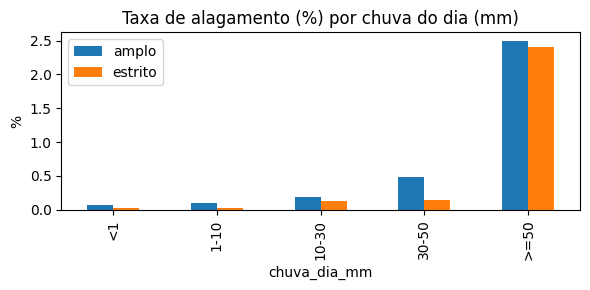

In [5]:
base_chuva = df[df["chuva_dia_mm"].notna()].copy()
faixas = pd.cut(base_chuva["chuva_dia_mm"], [-0.01, 1, 10, 30, 50, 1000], labels=["<1", "1-10", "10-30", "30-50", ">=50"])
tab = base_chuva.groupby(faixas).agg(linhas=("alagou", "size"), amplo=("alagou", "mean"), estrito=("alagou_estrito", "mean"))
tab[["amplo", "estrito"]] = (100 * tab[["amplo", "estrito"]]).round(3)
display(tab.rename(columns={"amplo": "% amplo", "estrito": "% estrito"}))
tab[["amplo", "estrito"]].plot(kind="bar", figsize=(6, 3), title="Taxa de alagamento (%) por chuva do dia (mm)")
plt.ylabel("%"); plt.tight_layout(); plt.show()

## 3. Preparação das variáveis
Algumas decisões para evitar resultados enganosos:
- Saem `n_registros_alag` e `n_registros_alag_estrito`. Elas contam os registros do próprio dia do alvo, então usá-las seria entregar a resposta ao modelo.
- Saem os identificadores e as colunas de controle: `bairro`, `regional`, `data`, `ano`, `horas_validas_dia`, `n_pontos_grade`, `local_casado`, além de `lat_centro` e `lon_centro`, que identificam o bairro e levariam o modelo a decorar lugares.
- Ficam só os dias com `chuva_dia_mm` medida. A estação falhou em cerca de 3,5% dos dias e, sem chuva, não há o que prever.
- O cenário B também tira `chuva_dia_mm`, `chuva_max_1h_mm` e as duas variáveis de maré na hora do pico de chuva, porque elas dependem de saber a chuva do dia.
- O histórico (`n_alag_*_365d` e `dias_desde_*`) já foi calculado só com dias anteriores, então não vaza o futuro.

In [6]:
base = df[df["chuva_dia_mm"].notna()].reset_index(drop=True)

EXCLUIR = ["bairro", "regional", "data", "ano", "alagou", "alagou_estrito", "n_registros_alag", "n_registros_alag_estrito",
           "horas_validas_dia", "n_pontos_grade", "lat_centro", "lon_centro", "local_casado"]
FEATURES_A = [c for c in base.columns if c not in EXCLUIR]
DEPENDEM_CHUVA_DO_DIA = ["chuva_dia_mm", "chuva_max_1h_mm", "mare_na_hora_pico_chuva_m", "mare_subindo_na_hora_pico"]
FEATURES_B = [c for c in FEATURES_A if c not in DEPENDEM_CHUVA_DO_DIA]

assert not any(c.startswith("n_registros") for c in FEATURES_A), "vazamento do alvo!"
print("linhas:", len(base), "| features A:", len(FEATURES_A), "| features B:", len(FEATURES_B))
print(FEATURES_A)

linhas: 219882 | features A: 33 | features B: 29
['chuva_dia_mm', 'chuva_max_1h_mm', 'chuva_d1_mm', 'chuva_ult3d_mm', 'chuva_ult7d_mm', 'chuva_ult15d_mm', 'chuva_ult30d_mm', 'n_alag_bairro_365d', 'dias_desde_ultimo_alag', 'n_bairros_alag_dia_anterior', 'mes', 'dia_do_ano_sin', 'dia_do_ano_cos', 'fase_lunar', 'sizigia', 'mare_max_dia_m', 'mare_min_dia_m', 'mare_amp_dia_m', 'mare_na_hora_pico_chuva_m', 'mare_subindo_na_hora_pico', 'n_alag_estrito_bairro_365d', 'dias_desde_ultimo_alag_estrito', 'area_km2', 'alt_media_m', 'alt_mediana_m', 'alt_min_m', 'alt_max_m', 'alt_desvio_m', 'alt_p10_m', 'pct_pontos_abaixo_5m', 'pct_area_faixa_marginal', 'dist_faixa_media_m', 'dist_faixa_min_m']


## 4. Modelos
Escolhemos dois modelos que funcionam bem com dados tabulares pequenos e desbalanceados.

**Regressão logística**, como referência fácil de interpretar. Ela não aceita vazios e é sensível à escala, então aplicamos log nas chuvas e nos "dias desde" (distribuições muito assimétricas), criamos um indicador de "nunca houve evento", imputamos a mediana (calculada só no treino) e padronizamos. O `class_weight="balanced"` compensa o desbalanceamento.

**Gradient boosting** (`HistGradientBoostingClassifier`). Aceita vazios direto e capta interações, como chuva forte combinada com bairro de faixa marginal. Usamos árvores rasas, folhas grandes e regularização, porque com tão poucos positivos o maior risco é o modelo decorar os dados. Os positivos são pesados pela raiz da razão de desbalanceamento, já que o peso cheio (~1.400×) tende a causar sobreajuste.

Para comparar, há também um baseline que não aprende nada: ele ordena só pela chuva do dia (cenário A) ou pela chuva acumulada dos 3 dias anteriores (cenário B). Se um modelo não supera o baseline, ele não acrescenta nada.

In [7]:
COLS_LOG = ["chuva_dia_mm", "chuva_max_1h_mm", "chuva_d1_mm", "chuva_ult3d_mm", "chuva_ult7d_mm", "chuva_ult15d_mm", "chuva_ult30d_mm"]
COLS_DIAS = ["dias_desde_ultimo_alag", "dias_desde_ultimo_alag_estrito"]

def preparar_logit(X):
    # transformacoes sem estado (nao dependem do treino, entao nao ha vazamento)
    X = X.copy()
    for c in COLS_DIAS:
        if c in X:
            X[c + "_nunca"] = X[c].isna().astype(int)
            X[c] = np.log1p(X[c].fillna(3650))                  # nunca houve evento -> 10 anos
    for c in COLS_LOG:
        if c in X:
            X[c] = np.log1p(X[c].clip(lower=0))
    for c in ["mare_na_hora_pico_chuva_m", "mare_subindo_na_hora_pico"]:
        if c in X:
            X[c + "_sem_chuva"] = X[c].isna().astype(int)       # sem chuva no dia -> sem hora de pico
            X[c] = X[c].fillna(0)
    return X

class Logit:
    def fit(self, X, y):
        self.m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                               LogisticRegression(class_weight="balanced", C=0.1, max_iter=500))
        self.m.fit(X, y); return self
    def predict_proba1(self, X): return self.m.predict_proba(X)[:, 1]

class Boosting:
    def fit(self, X, y):
        pos = max(int(y.sum()), 1); peso_pos = np.sqrt((len(y) - pos) / pos)
        w = np.where(y == 1, peso_pos, 1.0)
        self.m = HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=200, min_samples_leaf=200,
                                                l2_regularization=1.0, early_stopping=False, random_state=SEED)
        self.m.fit(X, y, sample_weight=w); return self
    def predict_proba1(self, X): return self.m.predict_proba(X)[:, 1]

MODELOS = {"logistica": (Logit, preparar_logit), "boosting": (Boosting, lambda X: X)}

## 5. Avaliação deixando um ano de fora
Para cada ano de 2014 a 2021, treinamos nos outros sete e prevemos o ano que ficou de fora. Depois juntamos as previsões de teste dos oito anos (*out-of-fold*) e calculamos as métricas uma única vez.

Métricas:
- **PR-AUC** (*average precision*): qualidade do ranking quando o positivo é raro. Um modelo aleatório teria PR-AUC igual à taxa de positivos (~0,1%), então valores bem acima disso são ganho real.
- **ROC-AUC:** complementa a anterior, mas costuma parecer otimista com classes raras.
- **recall@top1% e @top5%:** se alertássemos só os 1% (ou 5%) de bairro-dias com maior risco, que fração dos alagamentos reais seria pega? É o que mais se aproxima do uso pela Defesa Civil.

Um cuidado: deixar um ano de fora faz o treino usar anos posteriores ao testado. Aqui isso é aceitável porque as variáveis não dependem de previsões anteriores do modelo, mas na seção 8 fazemos também um teste estritamente cronológico.

In [8]:
def metricas(y, p):
    ordem = np.argsort(-p)
    out = {"PR-AUC": average_precision_score(y, p), "ROC-AUC": roc_auc_score(y, p), "taxa base": y.mean()}
    for q in (0.01, 0.05):
        k = int(len(p) * q); out[f"recall@top{int(q*100)}%"] = y[ordem[:k]].sum() / y.sum()
    return out

def oof(base, features, alvo, nome_modelo):
    Modelo, prep = MODELOS[nome_modelo]
    X = prep(base[features]); y = base[alvo].values
    p = np.full(len(base), np.nan)
    for tr, te in LeaveOneGroupOut().split(X, y, groups=base["ano"]):
        m = Modelo().fit(X.iloc[tr], y[tr])
        p[te] = m.predict_proba1(X.iloc[te])
    return p

CENARIOS = {"A (chuva do dia conhecida)": FEATURES_A, "B (sem previsao de chuva)": FEATURES_B}
BASELINE_COL = {"A (chuva do dia conhecida)": "chuva_dia_mm", "B (sem previsao de chuva)": "chuva_ult3d_mm"}

resultados, previsoes = [], {}
for alvo in ["alagou_estrito", "alagou"]:
    y = base[alvo].values
    for cen, feats in CENARIOS.items():
        b = base[BASELINE_COL[cen]].fillna(0).values
        resultados.append({"alvo": alvo, "cenario": cen, "modelo": "baseline (so chuva)", **metricas(y, b)})
        for nm in MODELOS:
            p = oof(base, feats, alvo, nm)
            previsoes[(alvo, cen, nm)] = p
            resultados.append({"alvo": alvo, "cenario": cen, "modelo": nm, **metricas(y, p)})
            print("ok:", alvo, cen, nm)

tabela = pd.DataFrame(resultados).set_index(["alvo", "cenario", "modelo"]).round(4)
display(tabela)

ok: alagou_estrito A (chuva do dia conhecida) logistica
ok: alagou_estrito A (chuva do dia conhecida) boosting
ok: alagou_estrito B (sem previsao de chuva) logistica
ok: alagou_estrito B (sem previsao de chuva) boosting
ok: alagou A (chuva do dia conhecida) logistica


KeyboardInterrupt: 

### Como ler a tabela
- Compare cada modelo com o baseline da mesma linha de alvo e cenário. O ganho em PR-AUC e em recall@top1% sobre o baseline é o que justifica usar aprendizado de máquina.
- O cenário A deve sair melhor que o B. A diferença mostra o quanto o projeto depende de uma boa previsão de chuva, que ainda precisa ser conseguida.
- O rótulo amplo e o estrito não se comparam direto em PR-AUC, porque as taxas-base são diferentes. Compare o ganho sobre o baseline de cada um.

## 6. Resultado por ano
O desempenho muda bastante de um ano para outro, principalmente porque o número de positivos muda (2018 tem só 1 positivo estrito). Anos com menos de 5 positivos não são confiáveis e estão marcados na tabela.

In [9]:
alvo, cen, nm = "alagou_estrito", "A (chuva do dia conhecida)", "boosting"
p = previsoes[(alvo, cen, nm)]
linhas = []
for ano, g in base.groupby("ano"):
    y = g[alvo].values
    if y.sum() == 0: continue
    pa = p[g.index]
    linhas.append({"ano": ano, "positivos": int(y.sum()), "PR-AUC": average_precision_score(y, pa),
                   "recall@top1%": y[np.argsort(-pa)[:int(len(pa) * 0.01)]].sum() / y.sum(),
                   "confiavel": "sim" if y.sum() >= 5 else "NAO (poucos positivos)"})
display(pd.DataFrame(linhas).round(3).set_index("ano"))

,positivos,PR-AUC,recall@top1%,confiavel
ano,,,,
2014,64,0.070,0.312,sim
2015,34,0.024,0.088,sim
2016,30,0.126,0.600,sim
2017,9,0.271,0.444,sim
2018,1,0.000,0.000,NAO (poucos positivos)
2019,17,0.051,0.471,sim
2020,5,0.006,0.200,sim
2021,2,0.010,0.500,NAO (poucos positivos)


## 7. Quais variáveis importam?
Esta seção responde a uma pergunta que ficou em aberto no documento do grupo: quais variáveis mais influenciam a previsão.

Usamos a importância por permutação. Em cada ano de teste, embaralhamos uma variável por vez e medimos quanto a PR-AUC cai: quanto maior a queda, mais o modelo dependia dela. O resultado é a média dos anos com pelo menos 5 positivos.

Variáveis correlacionadas (as várias janelas de chuva, as várias medidas de altitude) dividem a importância entre si, então nenhuma parece decisiva sozinha.

,queda media da PR-AUC
chuva_dia_mm,0.0795
dias_desde_ultimo_alag,0.0317
dist_faixa_min_m,0.0206
chuva_ult15d_mm,0.0197
alt_p10_m,0.0151
chuva_ult7d_mm,0.0145
mare_na_hora_pico_chuva_m,0.0097
alt_desvio_m,0.0096
fase_lunar,0.0090
dias_desde_ultimo_alag_estrito,0.0080


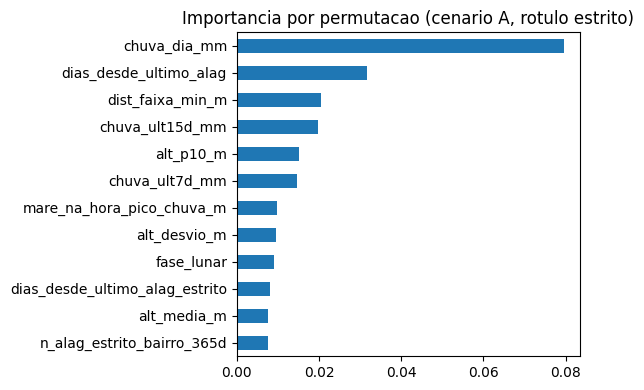

In [10]:
def importancia(base, features, alvo, repeticoes=3):
    X = base[features]; y = base[alvo].values
    queda = {f: [] for f in features}
    for tr, te in LeaveOneGroupOut().split(X, y, groups=base["ano"]):
        if y[te].sum() < 5: continue
        m = Boosting().fit(X.iloc[tr], y[tr])
        Xt, yt = X.iloc[te].copy(), y[te]
        ap0 = average_precision_score(yt, m.predict_proba1(Xt))
        for f in features:
            ganhos = []
            for _ in range(repeticoes):
                orig = Xt[f].values.copy()
                Xt[f] = RNG.permutation(orig)
                ganhos.append(ap0 - average_precision_score(yt, m.predict_proba1(Xt)))
                Xt[f] = orig
            queda[f].append(np.mean(ganhos))
    return pd.Series({f: np.mean(v) for f, v in queda.items()}).sort_values(ascending=False)

imp = importancia(base, FEATURES_A, "alagou_estrito")
display(imp.head(15).round(4).to_frame("queda media da PR-AUC"))
imp.head(12).iloc[::-1].plot(kind="barh", figsize=(6, 4), title="Importancia por permutacao (cenario A, rotulo estrito)")
plt.tight_layout(); plt.show()

## 8. Teste cronológico
Treinamos com 2014–2017 e testamos em 2018–2021, ou seja, prevendo o futuro em relação ao treino. É o teste mais próximo do uso real, mas o conjunto de teste tem poucos positivos. O resultado serve como sinal de coerência e não como medida precisa.

In [11]:
alvo = "alagou_estrito"
tr = (base["ano"] <= 2017).values; te = ~tr
for nm in MODELOS:
    Modelo, prep = MODELOS[nm]
    X = prep(base[FEATURES_A]); y = base[alvo].values
    m = Modelo().fit(X[tr], y[tr]); p = m.predict_proba1(X[te])
    print(nm, {k: round(v, 4) for k, v in metricas(y[te], p).items()}, "| positivos no teste:", int(y[te].sum()))
b = base.loc[te, "chuva_dia_mm"].values
print("baseline", {k: round(v, 4) for k, v in metricas(base.loc[te, alvo].values, b).items()})

logistica {'PR-AUC': 0.0073, 'ROC-AUC': 0.8418, 'taxa base': np.float64(0.0002), 'recall@top1%': np.float64(0.12), 'recall@top5%': np.float64(0.24)} | positivos no teste: 25
boosting {'PR-AUC': 0.0193, 'ROC-AUC': 0.833, 'taxa base': np.float64(0.0002), 'recall@top1%': np.float64(0.36), 'recall@top5%': np.float64(0.48)} | positivos no teste: 25
baseline {'PR-AUC': 0.007, 'ROC-AUC': 0.8938, 'taxa base': np.float64(0.0002), 'recall@top1%': np.float64(0.28), 'recall@top5%': np.float64(0.4)}


## 9. Níveis de risco (backlog 05)
O backlog pede níveis fáceis de entender. Como a probabilidade bruta é sempre minúscula (evento raro), os cortes são por posição no ranking, calculados sobre as previsões de teste:

| Nível | Critério (fatia das maiores pontuações) |
|---|---|
| 3 – muito alto | top 0,5% |
| 2 – alto | 0,5% a 2% |
| 1 – moderado | 2% a 7% |
| 0 – baixo | restante |

A tabela abaixo mostra, para cada nível, a taxa real de alagamento e a parcela dos eventos capturada. Os cortes são só uma proposta: o grupo e a Defesa Civil precisam decidir quanto alarme falso aceitam para reduzir omissões (a persona Camila pede exatamente isso). Quando houver previsão de chuva real, os cortes terão de ser recalibrados.

,linhas,eventos,taxa_%,% dos eventos
nivel,,,,
3,1100,45,4.09,27.8
2,3298,28,0.85,17.3
1,10994,24,0.22,14.8
0,204490,65,0.03,40.1


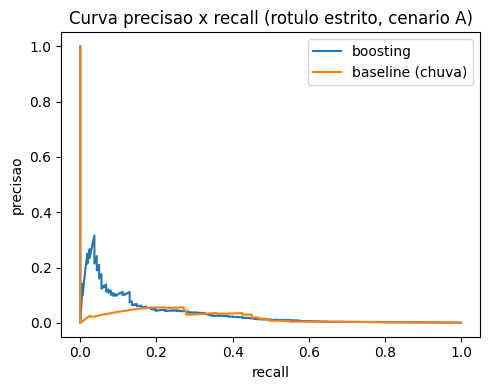

In [12]:
alvo, cen, nm = "alagou_estrito", "A (chuva do dia conhecida)", "boosting"
p = previsoes[(alvo, cen, nm)]; y = base[alvo].values
cortes = np.quantile(p, [0.93, 0.98, 0.995])
nivel = np.digitize(p, cortes)
niveis = pd.DataFrame({"nivel": nivel, "alagou": y}).groupby("nivel").agg(linhas=("alagou", "size"), eventos=("alagou", "sum"))
niveis["taxa_%"] = (100 * niveis["eventos"] / niveis["linhas"]).round(2)
niveis["% dos eventos"] = (100 * niveis["eventos"] / niveis["eventos"].sum()).round(1)
display(niveis.sort_index(ascending=False))

prec, rec, _ = precision_recall_curve(y, p)
b = base["chuva_dia_mm"].fillna(0).values
prec_b, rec_b, _ = precision_recall_curve(y, b)
plt.figure(figsize=(5, 4)); plt.plot(rec, prec, label="boosting"); plt.plot(rec_b, prec_b, label="baseline (chuva)")
plt.xlabel("recall"); plt.ylabel("precisao"); plt.title("Curva precisao x recall (rotulo estrito, cenario A)")
plt.legend(); plt.tight_layout(); plt.show()

## 10. Limitações
Vale ler isto antes de apresentar os números.
- O rótulo é um registro administrativo, não um alagamento medido. O modelo pode estar aprendendo onde a Defesa Civil atua e não onde alaga. Em 43 dos 291 positivos amplos com chuva medida, a estação registrou 0 mm.
- Há uma única estação de chuva (INMET A301) para a cidade toda. Todos os bairros recebem a mesma chuva no mesmo dia, e o modelo só os diferencia pelas características fixas e pelo histórico.
- A chuva do dia é observada, não prevista. O cenário A é um teto, e o B é mais realista enquanto não houver previsão.
- A maré é astronômica, sem efeito meteorológico, e não mostrou efeito claro na exploração.
- A altitude média do bairro é um mau indicador (o sinal saiu invertido). O ideal é a altitude relativa à drenagem (HAND), que ainda não foi calculada.
- Os dados vão só até 2021. Falta chuva de 2022 em diante (APAC/CEMADEN) para validar em dados recentes.
- Com 162 positivos estritos, as métricas têm muita incerteza. Diferenças pequenas entre modelos devem ser tratadas como empate.
